# 1. Data Setup & Inspection

In [61]:
import pandas as pd
import numpy as np

In [62]:
# Load the raw dataset
df = pd.read_csv('data/netflix_titles.csv')

# Check how many rows and columns we have
df.shape

(8807, 12)

In [63]:
# Look at the first 5 rows
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [64]:
# check data types and non-null counts
df.info()

# Count the missing values in each column
df.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [65]:
# Check the uniques types of content
print(df["type"].value_counts())
print("\n--- Ratings ---")
print(df["rating"].value_counts())

type
Movie      6131
TV Show    2676
Name: count, dtype: int64

--- Ratings ---
rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64


In [66]:
# Check for duplicate rows
print("Duplicates: ",df.duplicated().sum())

Duplicates:  0


### 🔍 Inspection Findings:
*   **Size:** The dataset contains 8,807 rows and 12 columns.
*   **Data Types:** `date_added`, `rating`, and `duration` are currently read as strings (`object`). They will need conversion.
*   **Missing Values:** 
    *   `director` has the highest amount of missing data (~30%).
    *   `country` and `cast` have under 10% missing.
    *   `date_added` has exactly 10 missing rows.
*   **The "Rating Bug":** The `rating` column contains three invalid values: `"74 min"`, `"84 min"`, and `"66 min"`. This directly corresponds to the missing values in the `duration` column. These were placed in the wrong column during data entry.
*   **Duplicates:** There are 0 duplicate rows.

# 2. Data Cleaning Pipeline

In [67]:
# a) Strip whitespace
str_cols = df.select_dtypes(include="string").columns
for col in str_cols:
    df[col] = df[col].str.strip()

# Verify
df["date_added"].head(3)

0    September 25, 2021
1    September 24, 2021
2    September 24, 2021
Name: date_added, dtype: str

In [68]:
# b) Parse dates and extract time features
df["date_added"] = pd.to_datetime(df["date_added"], format="mixed")
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month_name()

# Verify: Should print "Year range: 2008 to 2021"
print("Year range: ", df["year_added"].min(), "to", df["year_added"].max())

Year range:  2008.0 to 2021.0


In [69]:
# b2) Fix the rating bug
# 1. Create a mask to find where "min" is in the rating column
mask = df["rating"].str.contains("min", na=False)

# 2. Move the misplaced value to the duration column
df.loc[mask, "duration"] = df.loc[mask, "rating"]

# 3. Set the old rating to NaN (Not a Number / missing)
df.loc[mask, "rating"] = np.nan

# 4. Fill All missing ratings (including the new NaNs) with "Unknown"
df["rating"] = df["rating"].fillna("Unknown")

# Verify: Should print "Mins left in rating: 0"
print("Mins left in rating: ", df["rating"].str.contains("min", na=False).sum())

Mins left in rating:  0


In [70]:
# c) Handle missing values
# Fill categorical missing values with "Unknown"
for col in ["country", "director", "cast"]:
    df[col] = df[col].fillna("Unknown")

# Drop the ~10 rows missing the date_added column
df = df.dropna(subset=["date_added"])

# Verify: Check remaining missing values
print("Remaining missing values:\n")
print(df.isna().sum()[df.isna().sum() > 0]) 

Remaining missing values:

Series([], dtype: int64)


In [71]:
# d) Split duration into numbers
# Split the string by the space. dur[0] is the number, dur[1] is the word "min" or "Seasons"
dur = df["duration"].str.split(" ", expand=True)

# Convert the first column (the numbers) to actual numeric values
df["duration_num"] = pd.to_numeric(dur[0], errors="coerce")

# Create a column for Movies (duration in minutes) 
df["duration_min"] = np.where(df["type"] == "Movie", df["duration_num"], np.nan)

# Create a column for TV Shows (number of seasons)
df["duration_season"] = np.where(df["type"] == "TV Show", df["duration_num"], np.nan)

# Drop the temporary columns we just used 
df = df.drop(columns=["duration", "duration_num"])

# Verify: Look at the statistical summary for movie durations
df.loc[df["type"] == "Movie", "duration_min"].describe()

count    6131.000000
mean       99.564998
std        28.289504
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_min, dtype: float64

In [72]:
# e) Create new columns based on dates (Features Engineering)
# Calculate how many years it took for a title to reach Netflix
df["years_to_netflix"] = df["year_added"] - df["release_year"]

# Group release years into decades (e.g., 1994 becomes 1990)
df["decade"] = (df["release_year"] // 10) * 10

#Create a True\False column to esaily filter for recent content
df["is_recent"] = np.where(df["release_year"] >= 2015, True, False)

# Verify: Check the summary statistics for years_to_netflix
df["years_to_netflix"].describe()

count    8797.000000
mean        4.688417
std         8.786998
min        -3.000000
25%         0.000000
50%         1.000000
75%         5.000000
max        93.000000
Name: years_to_netflix, dtype: float64

In [73]:
# f) Drop duplicates just in case 
df = df.drop_duplicates()

# Print the final shape and list of columns
print("Final Cleaned Shape: ", df.shape)
print("\nColumns in the dataset:")
print(df.columns.tolist())

Final Cleaned Shape:  (8797, 18)

Columns in the dataset:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'listed_in', 'description', 'year_added', 'month_added', 'duration_min', 'duration_season', 'years_to_netflix', 'decade', 'is_recent']


### The Cleaning Pipeline Function
To ensure reproducibility, all data cleaning steps have been combined into a single, reusable function.

In [74]:
def clean_netflix(raw_df):
    """Cleans the Netflix titles DataFrame."""
    df = raw_df.copy() # Prevents SettingWithCopyWarning
    
    # a) Strip whitespace
    str_cols = df.select_dtypes(include="string").columns
    for col in str_cols:
        df[col] = df[col].str.strip()
        
    # b) Parse dates
    df["date_added"] = pd.to_datetime(df["date_added"], format="mixed")
    df["year_added"] = df["date_added"].dt.year
    df["month_added"] = df["date_added"].dt.month_name()
    
    # b2) Fix the rating bug
    mask = df["rating"].str.contains("min", na=False)
    df.loc[mask, "duration"] = df.loc[mask, "rating"]
    df.loc[mask, "rating"] = np.nan
    df["rating"] = df["rating"].fillna("Unknown")
    
    # c) Handle missing values
    for col in ["country", "director", "cast"]:
        df[col] = df[col].fillna("Unknown")
    df = df.dropna(subset=["date_added"])
    
    # d) Split duration
    dur = df["duration"].str.split(" ", expand=True)
    df["duration_num"] = pd.to_numeric(dur[0], errors="coerce")
    df["duration_min"] = np.where(df["type"] == "Movie", df["duration_num"], np.nan)
    df["n_seasons"] = np.where(df["type"] == "TV Show", df["duration_num"], np.nan)
    df = df.drop(columns=["duration", "duration_num"])
    
    # e) Feature engineering
    df["years_to_netflix"] = df["year_added"] - df["release_year"]
    df["decade"] = (df["release_year"] // 10) * 10
    df["is_recent"] = np.where(df["release_year"] >= 2015, True, False)
    
    # f) Drop duplicates
    df = df.drop_duplicates()
    
    return df

In [75]:
# 1. Load fresh raw data
raw_data = pd.read_csv("data/netflix_titles.csv")

# 2. Clean it using your new function
clean_df = clean_netflix(raw_data)

# 3. Verify the output
print("Original Shape:", raw_data.shape)
print("Cleaned Shape:", clean_df.shape)
print("\nAre there any missing ratings left? ", clean_df["rating"].str.contains("min").sum())

Original Shape: (8807, 12)
Cleaned Shape: (8797, 18)

Are there any missing ratings left?  0


# 3. Data Transformation (Explode & Merge)

In [76]:
# 1. Create a copy of the clean data just for genres
genres_df = clean_df[["show_id", "listed_in"]].copy()

# 2. Split the string by comma and explode it into separate rows
genres_df["genre"] = genres_df["listed_in"].str.split(", ")
genres_df = genres_df.explode("genre")

# 3. Strip whitespace and drop the old column
genres_df = genres_df.drop(columns=["listed_in"])

# Verify
print("Total unique genres: ", genres_df["genre"].nunique())
print(genres_df.head())

Total unique genres:  42
  show_id                   genre
0      s1           Documentaries
1      s2  International TV Shows
1      s2               TV Dramas
1      s2            TV Mysteries
2      s3          Crime TV Shows


In [77]:
# 1. Create a copy for countries
countries_df = clean_df[["show_id", "country"]].copy()

# 2. Split and explode
countries_df["country"] = countries_df["country"].str.split(", ")
countries_df = countries_df.explode("country")

# 3. Strip whitespace
countries_df["country"] = countries_df["country"].str.strip()

# Verify
print("Total unique countries:", countries_df["country"].nunique())
print(countries_df.head())

Total unique countries: 128
  show_id        country
0      s1  United States
1      s2   South Africa
2      s3        Unknown
3      s4        Unknown
4      s5          India


In [78]:
# 1. Create a mapping dictionary grouped by continent
continent_groups = {
    "North America": ["United States", "Canada", "Mexico"],
    "South America": ["Brazil", "Argentina", "Chile", "Colombia", "Peru", "Venezuela", "Uruguay"],
    "Europe": ["United Kingdom", "France", "Spain", "Germany", "Italy", "Poland", "Belgium", "Netherlands", "Sweden", "Denmark", "Norway", "Ireland", "Russia", "Austria", "Switzerland", "Portugal", "Finland", "Iceland", "Greece", "Romania", "Czech Republic", "Hungary", "Ukraine"],
    "Asia": ["India", "Japan", "South Korea", "China", "Taiwan", "Hong Kong", "Turkey", "Indonesia", "Philippines", "Thailand", "Vietnam", "Malaysia", "Singapore", "Pakistan", "Bangladesh", "Israel", "Saudi Arabia", "United Arab Emirates", "Jordan", "Lebanon", "Iraq", "Iran", "Kuwait", "Qatar", "Kazakhstan"],
    "Africa": ["Egypt", "Nigeria", "South Africa", "Kenya", "Morocco", "Ghana", "Tunisia", "Algeria", "Zimbabwe", "Senegal", "Cameroon"],
    "Oceania": ["Australia", "New Zealand", "Fiji"]
}

# 2. Flip the dictionary so we have {Country: Continent}
flipped_map = {country: continent for continent, countries in continent_groups.items() for country in countries}

# 3. Map it to our countries_df
countries_df["continent"] = countries_df["country"].map(flipped_map)

# 4. For any missing continents, fill them with "Other/Unknown"
countries_df["continent"] = countries_df["continent"].fillna("Other/Unknown")

# 5. Verify the results
print(countries_df["continent"].value_counts())

continent
North America    4297
Asia             2553
Europe           2247
Other/Unknown     940
Africa            309
South America     297
Oceania           192
Name: count, dtype: int64


In [79]:
# Check 1: Are we missing any titles?
print("Original titles:", clean_df["show_id"].nunique())
print("Titles in genre table:", genres_df["show_id"].nunique())

# Check 2: How many countries are unmatched?
unmatched = countries_df[countries_df["continent"] == "Other/Unknown"]
percent_unmatched = (len(unmatched) / len(countries_df)) * 100
print(f"Unmatched countries: {percent_unmatched:.2f}%")
print("Top unmatched countries:\n", unmatched["country"].value_counts().head())

Original titles: 8797
Titles in genre table: 8797
Unmatched countries: 8.68%
Top unmatched countries:
 country
Unknown       830
Luxembourg     12
Bulgaria       10
Serbia          7
Cambodia        5
Name: count, dtype: int64


# 4. Content Trends & Global Distribution

In [80]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a professional visual style
sns.set_theme(style="whitegrid")

<Figure size 1000x600 with 0 Axes>

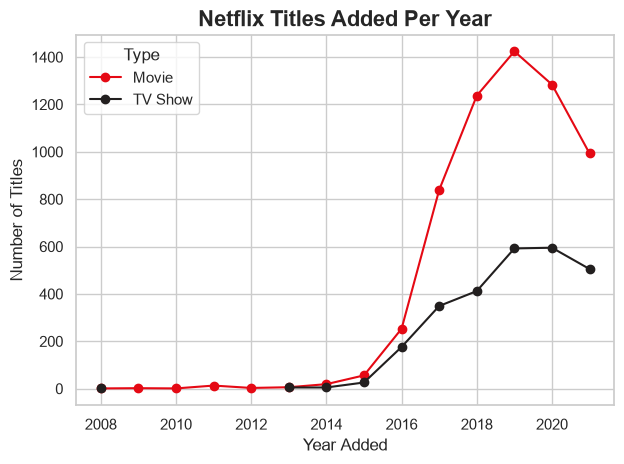

In [81]:
# 1. Group by year and type
yearly_titles = clean_df.groupby(["year_added", "type"]).size().unstack()

# 2. Plot 
plt.figure(figsize=(10, 6))
yearly_titles.plot(kind="line", marker="o", color=["#E50914", "#221F1F"]) 

# 3. Formatting 
plt.title("Netflix Titles Added Per Year", fontsize=16, fontweight="bold")
plt.xlabel("Year Added", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)
plt.legend(title="Type")
plt.tight_layout()
plt.show()

Takeaway: Netflix saw explosive growth in content additions from 2015 to 2019. While Movies have always been the majority, TV Shows saw a massive surge in 2019 and 2020, showing a shift in Netflix's content strategy.



C:\Users\pc\AppData\Local\Temp\ipykernel_24520\2749268939.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, palette="Reds_r")


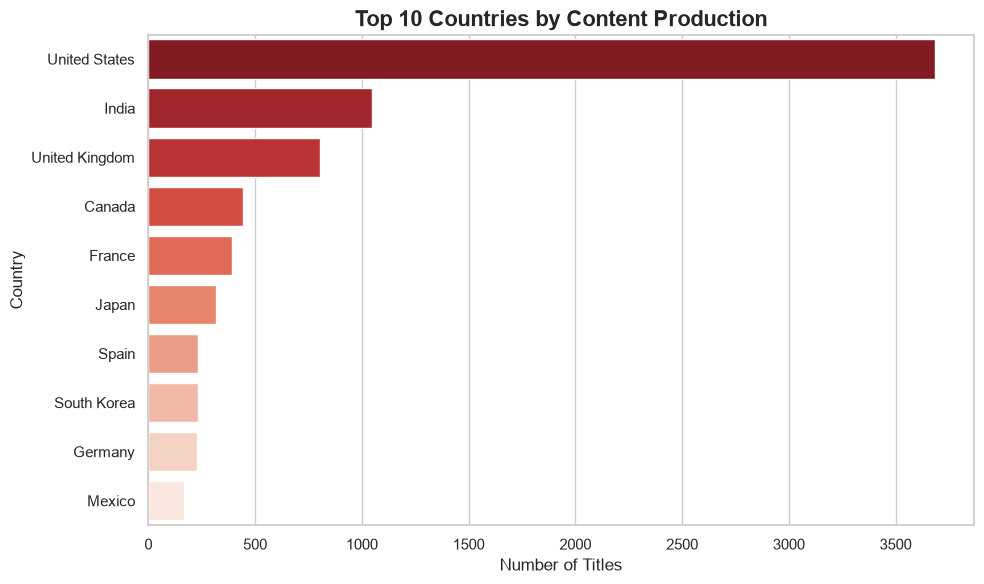

In [82]:
# 1. Get top 10 countries
top_countries = countries_df[countries_df["country"] != "Unknown"]["country"].value_counts().head(10)

# 2. Plot 
plt.figure(figsize=(10, 6))
sns.barplot(x=top_countries.values, y=top_countries.index, palette="Reds_r")

# 3. Formatting
plt.title("Top 10 Countries by Content Production", fontsize=16, fontweight="bold")
plt.xlabel("Number of Titles", fontsize=12)
plt.ylabel("Country", fontsize=12)
plt.tight_layout()
plt.show()

Takeaway: The United States is the dominant content producer on Netflix, followed by India and the United Kingdom. This highlights Netflix's strong domestic roots but also its aggressive expansion into international markets.

C:\Users\pc\AppData\Local\Temp\ipykernel_24520\2776173314.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_genres.values, y=top_genres.index, palette="Blues_r")


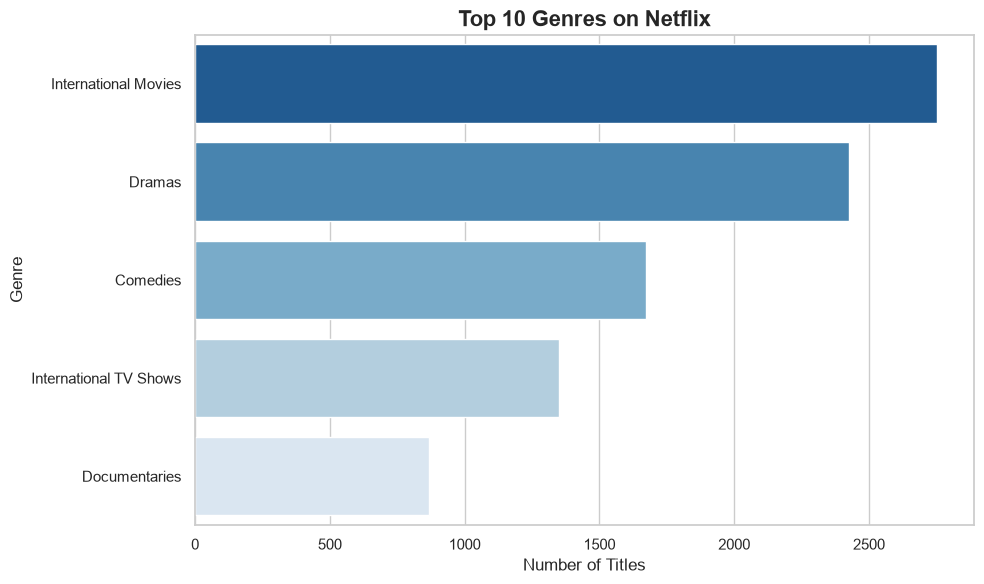

In [83]:
# 1. Get top 10 genres
top_genres = genres_df["genre"].value_counts().head()

# 2. Plot 
plt.figure(figsize=(10, 6))
sns.barplot(x=top_genres.values, y=top_genres.index, palette="Blues_r")

# 3. Formatting
plt.title("Top 10 Genres on Netflix", fontsize=16, fontweight="bold")
plt.xlabel("Number of Titles", fontsize=12)
plt.ylabel("Genre", fontsize=12)
plt.tight_layout()
plt.show()

Takeaway: International Movies, Dramas, and Comedies are the most dominant genres. This indicates that Netflix prioritizes broad, globally appealing content that crosses cultural boundaries.

C:\Users\pc\AppData\Local\Temp\ipykernel_24520\828409835.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=movies_df, x="decade", y="duration_min", palette="viridis")


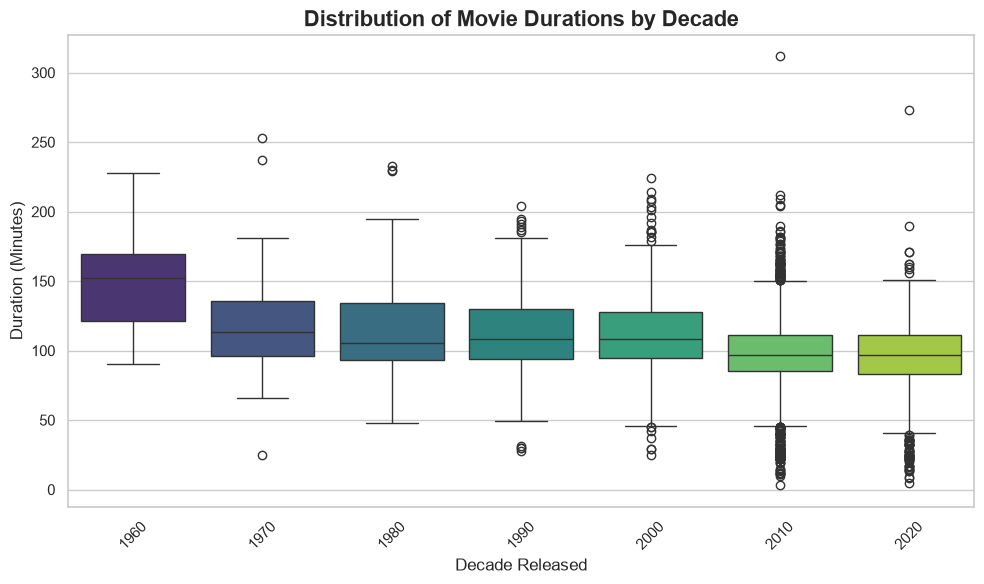

In [84]:
# 1. Filter for movies only, from the 1960s onwards
movies_df = clean_df[(clean_df["type"] == "Movie") & (clean_df["decade"] >= 1960)]

# 2. Plot 
plt.figure(figsize=(10, 6))
sns.boxplot(data=movies_df, x="decade", y="duration_min", palette="viridis")

# 3. Formatting
plt.title("Distribution of Movie Durations by Decade", fontsize=16, fontweight="bold")
plt.xlabel("Decade Released", fontsize=12)
plt.ylabel("Duration (Minutes)", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Takeaway: The median movie duration has remained relatively stable over the decades, hovering around 90-100 minutes. However, modern movies (2010s-2020s) show more extreme outliers, with some running over 200 minutes.

# 5. Ratings, Durations & Creators

<Figure size 1200x600 with 0 Axes>

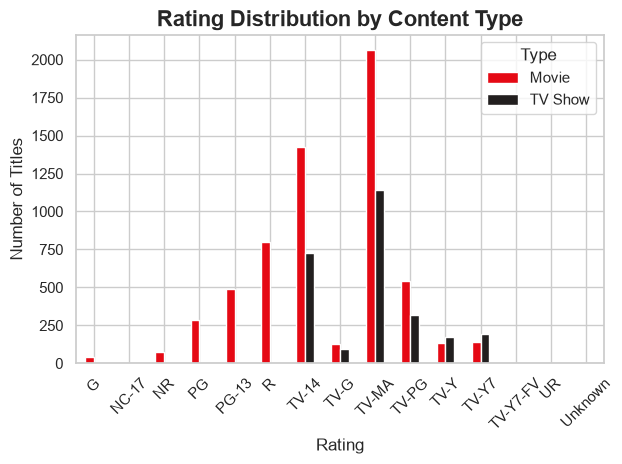

In [85]:
# 1. Group by rating and type, filling missing combinations with 0
rating_counts = clean_df.groupby(["rating", "type"]).size().unstack().fillna(0)

# 2. Plot a grouped bar chart 
plt.figure(figsize=(12, 6))
rating_counts.plot(kind="bar", color=["#E50914", "#221F1F"])

# 3. Formatting
plt.title("Rating Distribution by Content Type", fontsize=16, fontweight="bold")
plt.xlabel("Rating", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)
plt.xticks(rotation=45)
plt.legend(title="Type")
plt.tight_layout()
plt.show()

Takeaway: TV-MA and TV-14 are the most common ratings for both types of content, showing Netflix's strong focus on mature and teen audiences.

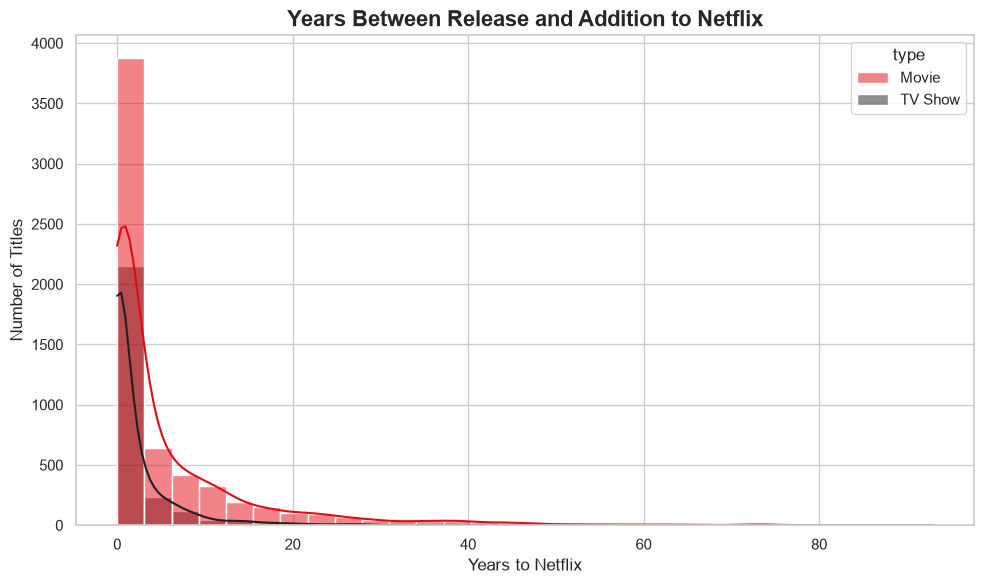

In [86]:
# 1.Remove negative values (data anomalies where year_added < release_year)
valid_delay = clean_df[clean_df["years_to_netflix"] >= 0]

# 2. Plot a histogram
plt.figure(figsize=(10, 6))
sns.histplot(data=valid_delay, x="years_to_netflix", hue="type", bins=30, kde=True, palette=["#E50914", "#221F1F"])

# 3. Formatting
plt.title("Years Between Release and Addition to Netflix", fontsize=16, fontweight="bold")
plt.xlabel("Years to Netflix", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)
plt.tight_layout()
plt.show()

Takeaway: The majority of content is added to Netflix within 0 to 5 years of its release. TV Shows tend to be added slightly faster than Movies.

<Figure size 1200x600 with 0 Axes>

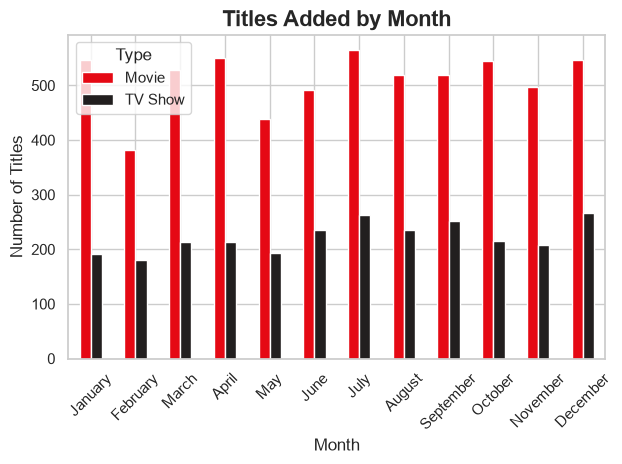

In [87]:
# 1. Define the chronological order of months
month_order = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]

# 2. Group by month and type, then reindex to sort correctly
monthly_titles = clean_df.groupby(["month_added", "type"]).size().unstack().reindex(month_order)

# 3. Plot 
plt.figure(figsize=(12, 6))
monthly_titles.plot(kind="bar", color=["#E50914", "#221F1F"])

# 4. Formatting
plt.title("Titles Added by Month", fontsize=16, fontweight="bold")
plt.xlabel("Month", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)
plt.xticks(rotation=45)
plt.legend(title="Type")
plt.tight_layout()
plt.show()

Takeaway: Netflix adds content consistently throughout the year, but there are noticeable spikes in January and December, likely aligning with holiday seasons.

C:\Users\pc\AppData\Local\Temp\ipykernel_24520\3158280447.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_directors.values, y=top_directors.index, palette="magma")


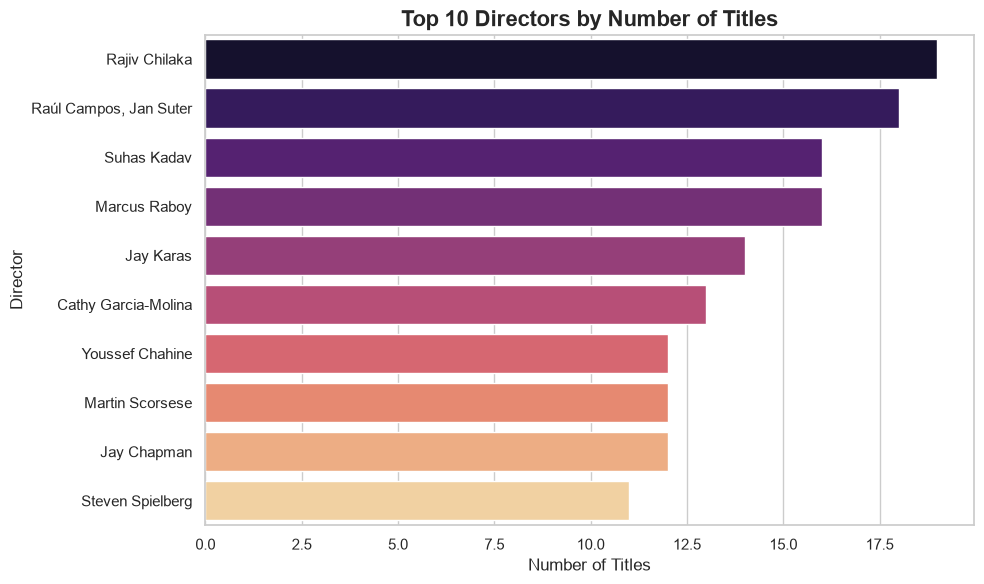

In [88]:
# 1. Filter out 'Unknown' directors and get the top 10
top_directors = clean_df[clean_df["director"] != "Unknown"]["director"].value_counts().head(10)

# 2. Plot 
plt.figure(figsize=(10, 6))
sns.barplot(x=top_directors.values, y=top_directors.index, palette="magma")

# 3. Formatting
plt.title("Top 10 Directors by Number of Titles", fontsize=16, fontweight="bold")
plt.xlabel("Number of Titles", fontsize=12)
plt.ylabel("Director", fontsize=12)
plt.tight_layout()
plt.show()

Takeaway: A few prolific directors have massive catalogs on Netflix. This suggests that Netflix often signs multi-project deals with specific creators to build a consistent library of content.

# 6. Advanced Analysis: Genre by Continent 

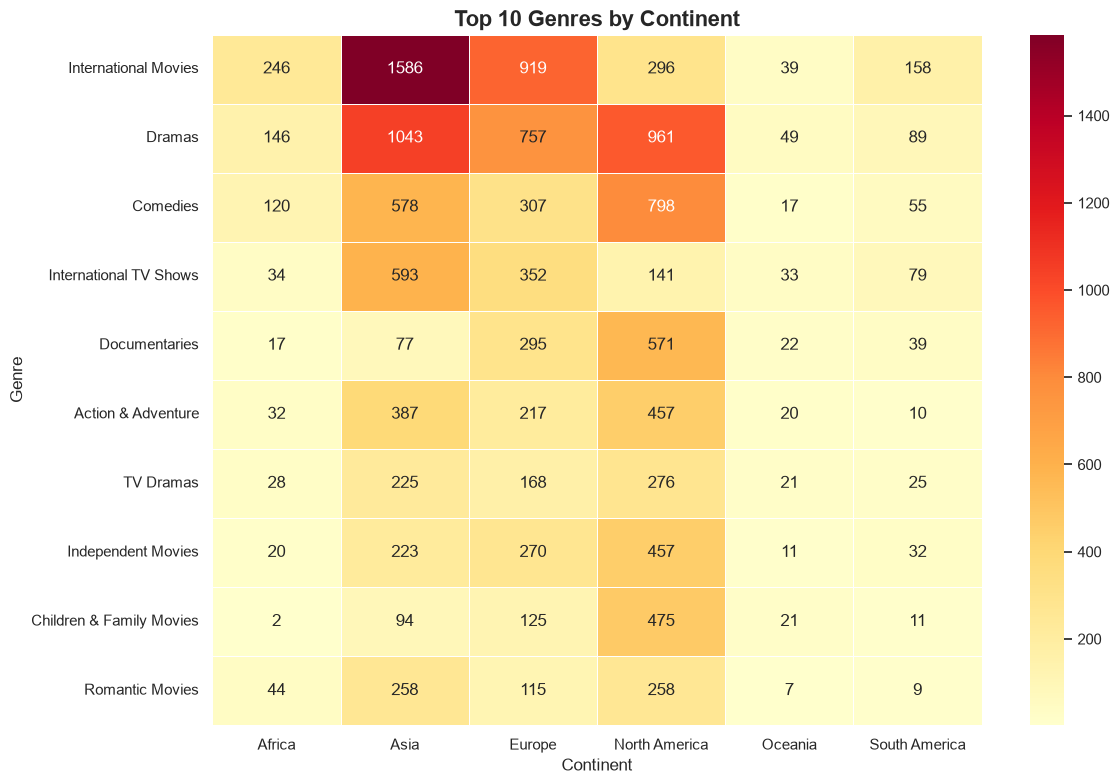

In [90]:
# 1. Merge the tow dataframes on 'show_id'
# We only want real countries, so drop 'Unknown'
merged_df = genres_df.merge(countries_df, on="show_id")
merged_df = merged_df[merged_df["continent"] != "Other/Unknown"]

# 2. Create a pivot table (a cross-tabulations)
# Rows = Genres, Columns = Continents
heatmap_data = pd.crosstab(merged_df["genre"], merged_df["continent"])

# 3. Filter to only show the Top 10 Genres to keep the chart readable 
top_10_genres = genres_df["genre"].value_counts().head(10).index
heatmap_data = heatmap_data.loc[top_10_genres]

# 4. Plot the Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, cmap="YlOrRd", annot=True, fmt="d", linewidths=.5)

plt.title("Top 10 Genres by Continent", fontsize=16, fontweight="bold")
plt.xlabel("Continent", fontsize=12)
plt.ylabel("Genre", fontsize=12)
plt.tight_layout()
plt.show()


Takeaway: The heatmap reveals that Dramas and International Movies are heavily concentrated in Asia and Europe. North America shows a strong preference for Comedies and Documentaries compared to other regions.

# 8. Advanced Analysis: NLP on Descriptions

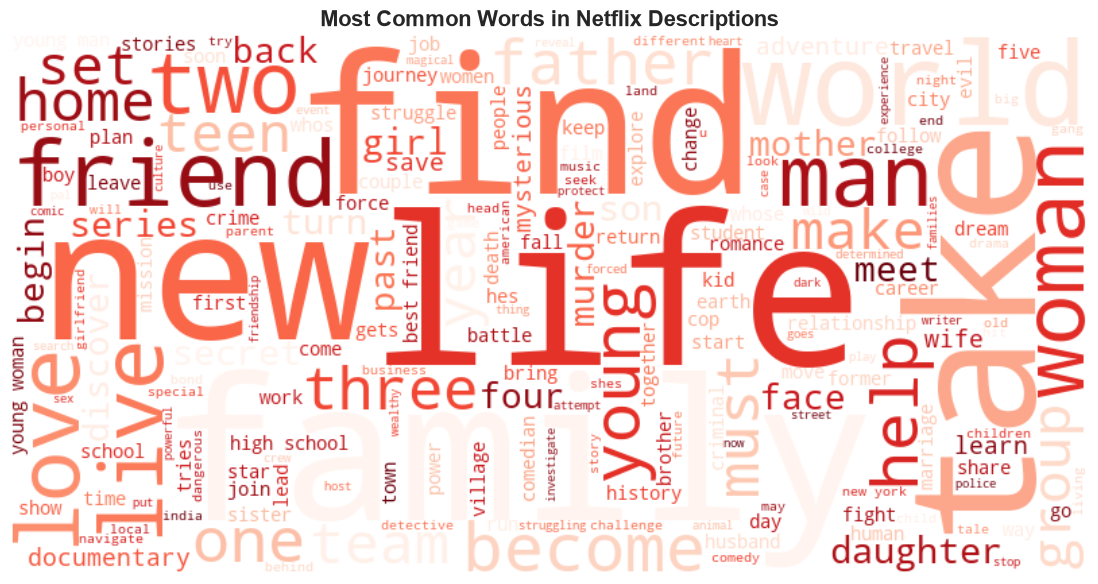

In [91]:
from wordcloud import WordCloud
from collections import Counter
import re

# 1. Combine all descriptions into one giant string
all_text = " ".join(clean_df["description"].dropna().astype(str))

# 2. Clean the text: remove punctuation and make it lowercase
all_text = re.sub(r'[^\w\s]', '', all_text).lower()

# 3. Split into individual words
words = all_text.split()

# 4. Remove common "stop words" (words like 'the', 'and', 'a')
stop_words = set(["the", "and", "a", "to", "of", "in", "is", "for", "on", "with", "as", "by", "an", "their", "his", "her", "from", "who", "when", "that", "this", "it"])
filtered_words = [word for word in words if word not in stop_words]

# 5. Generate the Word Cloud
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='Reds').generate(" ".join(filtered_words))

# 6. Plot it
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off') # Hide the axes
plt.title("Most Common Words in Netflix Descriptions", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

Takeaway: The word cloud highlights that Netflix descriptions frequently use words related to "life", "family", "love", and "world". This shows that the platform's content leans heavily into emotional, human-centric storytelling.